# __Hadoop, Spark__


## __Тема 1. Введение в большие данные. Hadoop, MapReduce__
## __ЛР: Многошаговый MapReduce в `mrjob`__

### Элементы функционального программирования

__Функциональное программирование__ — парадигма программирования, в которой процесс выполнения программы трактуется как вычисление значений функций.

Функциональное программирование предполагает обходиться вычислением результатов функций от исходных данных и результатов других функций, и не предполагает явного хранения состояния программы.

#### Функция `map()`

Можно написать функцию `apply_f_to_everything_in`, которая применяет некоторую функцию (первый параметр) к итерируемому объекту (второй параметр):

In [1]:
def apply_f_to_everything_in(f, data):
    result = []
    for x in data:
        result.append(f(x))
    return result

В языке Python имеется встроенная функция `map()`, которая применяет другую функцию к итерируемому объекту и которая значительно эффективнее приведенного ранее варианта функции `apply_f_to_everything_in`:

In [2]:
map(lambda x: x**3+1, [1, 2, 3, 4, 5])

Особенностью `map()` является «ленивые вычисления» или «отложенные вычисления» (Lazy Evaluation) — стратегия, согласно которой вычисления следует откладывать до тех пор, пока не понадобится их результат. Это позволяет повысить производительность, ограничивая выполнение вычислений только теми ситуациями, когда они действительно необходимы.

Поэтому вместо обработанного объекта по умолчанию нам возвращается ссылка на итератор (объект-генератор). Пока мы не обернем ссылку в функцию `list()` или другую функцию (метод), обработка объекта данных  функцией-аргументом функции `map()` не производится.

In [3]:
list(map(lambda x: x**3+1, [1, 2, 3, 4, 5]))

[2, 9, 28, 65, 126]

Функция `map()` применяет функцию-аргумент к каждому элементу последовательности и возвращает итератор с результатами.

Например, с помощью `map()` можно выполнять преобразования элементов, в частности, перевести все строки в верхний регистр:

In [4]:
list_of_words = ['one', 'two', 'list', '', 'dict']

list(map(str.upper, list_of_words))

['ONE', 'TWO', 'LIST', '', 'DICT']

Или выполнить  конвертацию текста в числа:

In [5]:
list_of_str = ['1', '2', '5', '10']

list(map(int, list_of_str))

[1, 2, 5, 10]

Если функция, которую использует `map()`, ожидает два аргумента, то передаются два списка:

In [6]:
nums1 = [1, 2, 3, 4, 5]
nums2 = [100, 200, 300, 400, 500]

list(map(lambda x, y: x*y, nums1, nums2))

[100, 400, 900, 1600, 2500]

Вместо функции `map()` часто можно использовать списковое включение (list comprehension), например:

In [7]:
[x*y for x, y in zip(nums1, nums2)]

[100, 400, 900, 1600, 2500]

Но функция `map()` может быть эффективнее в том случае, когда надо обработать большое количество элементов, так как функция `map()` создает итератор, допускающий отложенные вычисления, а списковое включение генерирует список, сразу производя все вычисления.

#### Функция `filter()`

Функция `filter()` применяет функцию-аргумент ко всем элементам последовательности и возвращает итератор с теми объектами, для которых функция-аргумент вернула `True`.

Например, требуется вернуть только те строки, в которых находятся числа:

In [8]:
list_of_strings = ['one', 'two', 'list', '', 'dict', '100', '1', '50']

list(filter(str.isdigit, list_of_strings))

['100', '1', '50']

Пусть из списка чисел нужно оставить только нечетные числа:

In [9]:
list(filter(lambda x: x%2==1, [10, 111, 102, 213, 314, 515]))

[111, 213, 515]

Или только четные:

In [10]:
list(filter(lambda x: x%2==0, [10, 111, 102, 213, 314, 515]))

[10, 102, 314]

Из списка слов оставить только те, у которых количество букв больше двух:

In [11]:
list_of_words = ['one', 'two', 'list', '', 'dict']

list(filter(lambda x: len(x) > 2, list_of_words))

['one', 'two', 'list', 'dict']

### Генераторы

Генераторы - это специальный класс функций, который позволяет легко создавать свои итераторы. В отличии от обычных функций, генератор не просто вычисляет и возвращает значение (или список значений) и завершает работу, а создает и возвращает итератор, который будет вычислять и отдавать значения по одному.

В функции-генераторе присутствует ключевое слово `yield` (вместо `return`). При вызове эта функция возвращает объект-генератор, который является итератором.

Обычная функция завершает свою работу, если:

* встретилось выражение `return`
* закончился код функции (эквивалентно конструкции `return None`)
* возникло исключение (ошибка)

После выполнения функции управление возвращается в вызывающий код и программа выполняется дальше. Все аргументы, которые передавались в функцию, и локальные переменные, созданные в функции, теряются и остается только результат, который вернула функция.

Функция может возвращать список элементов, несколько объектов или возвращать разные результаты, в зависимости от аргументов, но она всегда возвращает какой-то один результат.

Генератор же генерирует значения. При этом значения возвращаются по запросу и после возврата одного значения, выполнение функции-генератора приостанавливается до запроса следующего значения. Между запросами генератор сохраняет свое состояние.

С точки зрения синтаксиса, генератор выглядит как обычная функция. Но вместо `return` используется оператор `yield`.

Каждый раз, когда внутри функции встречается `yield`, генератор приостанавливается и возвращает значение. При следующем запросе, генератор начинает работать с того же места, где он завершил работу в прошлый раз.

Так как `yield` не завершает работу генератора, он может использоваться несколько раз.

In [12]:
def simple_generator():
    x = 1
    yield x
    yield x + 1
    yield x + 2

In [13]:
gen_obj = simple_generator()
gen_obj

<generator object simple_generator at 0x11369a3b0>

Теперь можно выполнить цикл по объекту-генератору (только один раз!):

In [14]:
for x in gen_obj:
    print(x)

1
2
3


Повторное обращение к объекту-генератору ничего не даст, так как объект-генератор уже исчерпан и должен быть повторно инициализирован.

In [15]:
for x in gen_obj:
    print(x)

Ключевое слово `yield` позволяет вернуть значение из функции, не разрушая состояние ее локальных переменных.

Когда `return` в функции заменяется на `yield`, это заставляет функцию передавать объект-генератор вызывающему коду.
Фактически `yield` приостанавливает завершение функции до следующего вызова функции `next()`. При вызове функция начнет выполняться с того места, где она была приостановлена.

In [16]:
def gen_func():
  num = 3
  print("Первый вызов функции")
  yield num
  print("Второй вызов функции")
  yield num**2
  print("Третий вызов функции")
  yield num**3

In [17]:
obj = gen_func()
obj

<generator object gen_func at 0x11369a810>

Чтобы получить доступ к итератору `obj`, можно использовать  функцию `next()`. Функция-генератор будет исполняться до тех пор, пока не будет достигнут следующий оператор `yield`.

In [18]:
print(next(obj))

Первый вызов функции
3


In [19]:
print(next(obj))

Второй вызов функции
9


In [20]:
print(next(obj))

Третий вызов функции
27


После исчерпания всех операторов `yield` в функции-генераторе при очередном вызове функции `next()` будет выдана ошибка.

In [21]:
try:
    print(next(obj))
except Exception as err:
    print(f"ОШИБКА: {err}")

ОШИБКА: 


Объект-генератор можно полностью использовать только один раз. Если необходимо его повторное использование, нужно снова создать объект-генератор.

В качестве примера создадим функцию-генератор, которая будет возвращать кубы чисел по одному, используя ключевое слово `yield`. При этом память будет выделяться только для того элемента, который вычисляется, после возвращения этого элемента память будет удалена:

In [22]:
def cub_var():
    i = 1
    while True:
        yield i*i*i
        i += 1

In [23]:
for num in cub_var():
    if num > 1000:
        break
    print(num)

1
8
27
64
125
216
343
512
729
1000


Генераторы могут быть конвейеризованы (один генератор использует другой) как последовательность операций в одном коде. Конвейерная обработка также делает код более эффективным и легким для чтения.
Для конвейеризации можно использовать скобки `()`, чтобы указать функцию-генератор внутри другой функции-генератора.

In [24]:
def gen_1(n):
    for i in range(n):
        yield i

def gen_2(gen):
    for n in gen:
        if n % 2: # true when n is odd
            yield n

In [25]:
for i in gen_2(gen_1(10)):
    print(i)

1
3
5
7
9


## Функция `reduce()`

Функция `reduce()` модуля `functools` кумулятивно применяет функцию `function` к элементам итерируемой последовательности `iterable`, сводя её к единственному значению.

`reduce(function, iterable[, initializer])`

* `function` - функция, которую требуется применить к элементам последовательности `iterable`. Должна принимать два аргумента, где первый аргумент — аккумулированное ранее значение, а второй — следующий элемент последовательности.

* `iterable` - последовательность, элементы которой требуется свести к единственному значению. Если последовательность пуста и не задано начальное значение `initializer`, то возбуждается исключение `TypeError`.

* `initializer=None` - базовое значение, с которого требуется начать отсчёт. Оно же будет возвращено, если последовательность пуста.

Функция `reduce()` эквивалентна следующему коду:
```python
def reduce(function, iterable, initializer=None):
    it = iter(iterable)
    if initializer is None:
        value = next(it)
    else:
        value = initializer
    for element in it:
        value = function(value, element)
    return value
```

In [26]:
from functools import reduce

def do_reduce(a, b):
    print('do_reduce({}, {})'.format(a, b))
    return a + b

In [27]:
data = range(1, 6)
print(list(data))

[1, 2, 3, 4, 5]


In [28]:
result = reduce(do_reduce, data)
print('result: {}'.format(result))

do_reduce(1, 2)
do_reduce(3, 3)
do_reduce(6, 4)
do_reduce(10, 5)
result: 15


In [29]:
print(reduce(do_reduce, data, 100))

do_reduce(100, 1)
do_reduce(101, 2)
do_reduce(103, 3)
do_reduce(106, 4)
do_reduce(110, 5)
115


In [30]:
print(reduce(do_reduce, [13]))

13


In [31]:
try:
    print('Empty sequence:', reduce(do_reduce, []))
except TypeError as err:
    print('ERROR: {}'.format(err))

ERROR: reduce() of empty iterable with no initial value


In [32]:
print(reduce(do_reduce, [], 100))

100


Вычислим произведение всех элементов списка при помощи `reduce()`:

In [33]:
items = [1, 2, 3, 4, 5]
mult_all = reduce(lambda x,y: x * y, items)
mult_all

120

Вычислим наибольший элемент в списке при помощи `reduce()`:

In [34]:
items = [1, 24, 17, 14, 9, 32, 2]

all_max = reduce(lambda a,b: a if (a > b) else b, items)
all_max

32

Функции `map`, `filter` и `reduce` являются частью парадигмы функционального программирования. Они позволяют программисту писать более простой и короткий код без необходимости беспокоиться о таких сложностях, как циклы и ветвления.

По сути, эти три функции позволяют вам применять функцию ко многим итерациям за один полный цикл. Функции `map` и `filter` встроены в Python (в модуль `__builtins__`) и не требуют импорта, однако функцию `reduce` необходимо импортировать, поскольку она находится в модуле `functools`.

### Обработка данных большого размера

Часто в Data Science мы имеем дело с таким с огромным количеством данных, что многие методы их обработки не работают или невозможны в реализации. Огромное количество данных — это хорошо, это очень хорошо, и мы хотим использовать как можно больше.

Давайте начнем с простой задачи. Вам дан список строк, и вам нужно вернуть самую длинную строку. Это довольно легко сделать в Python:

In [35]:
def find_longest_string(list_of_strings):
    longest_string = None
    longest_string_len = 0
    for s in list_of_strings:
        if len(s) > longest_string_len:
            longest_string_len = len(s)
            longest_string = s
    return longest_string

Мы перебираем строки по очереди, вычисляем длину и сохраняем самую длинную строку, пока не закончим.

Для небольших списков это работает довольно быстро:

In [36]:
list_of_strings = ['abc', 'python', 'dima']
%time print(find_longest_string(list_of_strings))

python
CPU times: user 139 μs, sys: 85 μs, total: 224 μs
Wall time: 200 μs


Даже для списков с более чем 3 элементами это работает довольно хорошо, здесь мы попробуем с 3000 элементами:

In [37]:
medium_list_of_strings = list_of_strings*3000
%time print(find_longest_string(medium_list_of_strings))

python
CPU times: user 378 μs, sys: 3 μs, total: 381 μs
Wall time: 384 μs


Но что если мы попробуем 300 миллионов элементов?

In [38]:
large_list_of_strings = list_of_strings*300000000
%time print(find_longest_string(large_list_of_strings))

python
CPU times: user 35.1 s, sys: 1.1 s, total: 36.2 s
Wall time: 37.2 s


Это уже проблема. В большинстве приложений время ответа около 20 секунд не приемлемо. Один из способов сократить время вычислений — купить гораздо более быстрый процессор. Масштабирование вашей системы путем внедрения более качественного и быстрого оборудования называется «Вертикальное масштабирование». Это, конечно, не будет работать вечно. Во-первых, не так просто найти процессор, который работает в 10 раз быстрее. Во-вторых, наши данные, вероятно, будут увеличиваться, и мы не хотим менять наш процессор каждый раз, когда ощущаем что наш код недостаточно быстрый. Такое решение не масштабируемое. Вместо этого мы можем выполнить «Горизонтальное масштабирование»: мы разработаем наш код так, чтобы он мог работать параллельно, и он станет намного быстрее, когда мы добавим больше процессоров.

## Разбиение кода

Нам нужно разбить наш код на более мелкие компоненты и решить, как мы можем распараллелить вычисления. Идея такова:

1) разбить наши данные на множество блоков,  
2) выполнить функцию `find_longest_string` для каждого блока параллельно и  
3) найти самую длинную строку среди выходных данных всех блоков.  

Наш код функции имеет очень узкое применение, поэтому вместо использования функции `find_longest_string` мы разработаем более общую структуру, которая поможет нам выполнять различные параллельные вычисления для больших данных.

В нашем коде мы делаем две основные вещи: вычисляем `len` строки и сравниваем ее с самой длинной до сих пор строкой. Мы разбиваем наш код на два этапа:

    1) вычисляем `len` всех строк и  
    2) выбираем значение `max`.  

In [39]:
%%time
# шаг 1:
list_of_string_lens = [len(s) for s in list_of_strings]
list_of_strings_and_lens = zip(list_of_strings, list_of_string_lens)
# шаг 2:
max_len = max(list_of_strings_and_lens, key=lambda t: t[1])
print(max_len)

('python', 6)
CPU times: user 212 μs, sys: 178 μs, total: 390 μs
Wall time: 540 μs


Здесь рассчитываем длину строк, а затем сворачиваем их вместе функцией `zip`. Это намного быстрее, чем делать это в одной строке и дублировать список строк.

В этом состоянии код работает на самом деле медленнее, чем раньше, потому что вместо того, чтобы выполнить один проход для всех наших строк, мы делаем это 2 раза, сначала для вычисления `len`, а затем для поиска `max` значения. Почему это хорошо для нас? Потому что теперь наш «шаг 2» получает в качестве входных данных не исходный список строк, а некоторые предварительно обработанные данные. Это позволяет нам выполнить второй шаг, используя выходные данные другого «второго шага»! Мы лучше поймем это немного позже, сначала давайте дадим имя этим шагам. Мы будем называть первый шаг __«mapper»__, потому что он отображает какое-то одно значение в какое-то другое значение, а второй шаг мы будем называть __«reducer»__, потому что он получает список значений и выдает одно (в большинстве случаев) значение. Вот две вспомогательные функции для `mapper` и `reducer`:

In [40]:
mapper = len

def reducer(p, c):
    if p[1] > c[1]:
        return p
    return c

Функция `mapper` — это просто функция `len`. Она получает строку и возвращает ее длину. Функция `reducer` получает два кортежа в качестве входных данных и возвращает один с наибольшей длиной.

Перепишем наш код, используя встроенные в Python функции `map` и `reduce` (функцию `reduce` нужно импортировать из `functools`):

In [41]:
%%time

# шаг 1
mapped = zip(list_of_strings, map(mapper, list_of_strings))

# шаг 2:
reduced = reduce(reducer, mapped)

print(reduced)

('python', 6)
CPU times: user 31 μs, sys: 6 μs, total: 37 μs
Wall time: 36.7 μs


Код делает то же самое, но выглядит немного изящнее, а главное — он более универсален и поможет нам распараллелить вычисления. Давайте посмотрим на это более внимательно:

Шаг 1 отображает наш список строк в список кортежей с помощью функции `mapper` (здесь я снова использую `zip`, чтобы избежать дублирования строк).

Шаг 2 использует функцию `reducer`, переходит по кортежам с первого шага и применяет их один за другим. Результатом является кортеж с максимальной длиной.

Теперь давайте разберем наш ввод по частям и поймем, как он работает, прежде чем проводить какое-либо распараллеливание (мы будем использовать `chunkify`, который разбивает большой список на куски одинакового размера):

In [42]:
my_list = \
"""
Объединяя знанием людей разных культур,
РУДН формирует лидеров, которые делают мир лучше. Ура!!!
""".split()
my_list

['Объединяя',
 'знанием',
 'людей',
 'разных',
 'культур,',
 'РУДН',
 'формирует',
 'лидеров,',
 'которые',
 'делают',
 'мир',
 'лучше.',
 'Ура!!!']

In [43]:
# Yield successive n-sized
# chunks from l.
def chunkify_list(a_list, number_of_chunks=4):
    # looping till length of a_list
    for i in range(0, len(a_list), number_of_chunks):
        yield a_list[i:i + number_of_chunks]

# How many elements each
# list should have
n = 5

x = list(chunkify_list(my_list, n))
print (x)

[['Объединяя', 'знанием', 'людей', 'разных', 'культур,'], ['РУДН', 'формирует', 'лидеров,', 'которые', 'делают'], ['мир', 'лучше.', 'Ура!!!']]


In [44]:
data_chunks = chunkify_list(my_list, number_of_chunks=8)

#step 1:
reduced_all = []
for chunk in data_chunks:
    mapped_chunk = map(mapper, chunk)
    mapped_chunk = zip(chunk, mapped_chunk)
    reduced_chunk = reduce(reducer, mapped_chunk)
    reduced_all.append(reduced_chunk)

#step 2:
reduced = reduce(reducer, reduced_all)

print(reduced)

('формирует', 9)


На первом шаге мы просматриваем фрагменты и находим самую длинную строку в этом фрагменте, используя `mapper`, и уменьшаем. На втором шаге мы берем выходные данные первого шага, которые представляют собой список уменьшенных значений, и выполняем окончательное уменьшение, чтобы получить самую длинную строку. Используется  `number_of_chuncks=8`, потому что это количество высокопроизводительных физических ядер CPU на ноутбуке.

## Параллельные и распределенные вычисления с Map-Reduce

__MapReduce__ — это парадигма программирования, которая позволяет масштабировать данные на сотни или тысячи серверов для аналитики больших данных.

В двух словах, термин «MapReduce» относится к двум различным заданиям. Первое — это задание __Map__, которое берет набор данных и преобразует его в другой набор данных, где отдельные элементы разбиваются на кортежи (пары ключ/значение), в то время как второе задание __Reduce__ берет выходные данные задания __Map__ в качестве входных данных и объединяет эти кортежи данных в меньший набор кортежей.

### Параллельная и распределенная обработка

Парадигма программирования __MapReduce__ разработана для обеспечения параллельной и распределенной обработки больших наборов данных, которые классифицируются как __большие данные__. __MapReduce__ позволяет нам преобразовывать такие большие наборы данных в наборы кортежей в формате пар __ключ:значение__. Эти пары аналогичны структуре данных в словарях Python и файлах JSON. Эти кортежи сопоставляются и сокращаются в вычислительной среде, чтобы обеспечить распределенное выполнение сложных задач в группе (кластере) взаимосвязанных компьютеров.

Итак, __MapReduce__ использует параллельные распределенные вычисления для преобразования больших данных в обычные данные.

Давайте сначала посмотрим, что подразумевается под параллельной и распределенной обработкой.

### Распределенные системы обработки

__Распределенная система обработки__ — это группа компьютеров в сети, работающих в тандеме для выполнения задачи.

Когда компьютеры находятся в распределенной системе, они не разделяют память жесткого диска или процессорную память; они общаются друг с другом посредством сообщений, которые передаются по сети. Отдельные компьютеры в этой сети называются __узлами__. Компьютеры могут отправлять запросы, а также пакеты данных друг другу.

Два наиболее распространенных способа организации компьютеров в распределенную систему — это __система клиент/сервер__ и __одноранговая система__.

Система клиент-сервер имеет узлы, которые отправляют запросы центральному серверу. Затем сервер решает принять или отклонить эти запросы и отправить или нет дополнительные данные внешним узлам.

Одноранговые системы позволяют узлам общаться друг с другом напрямую, не требуя одобрения сервера.

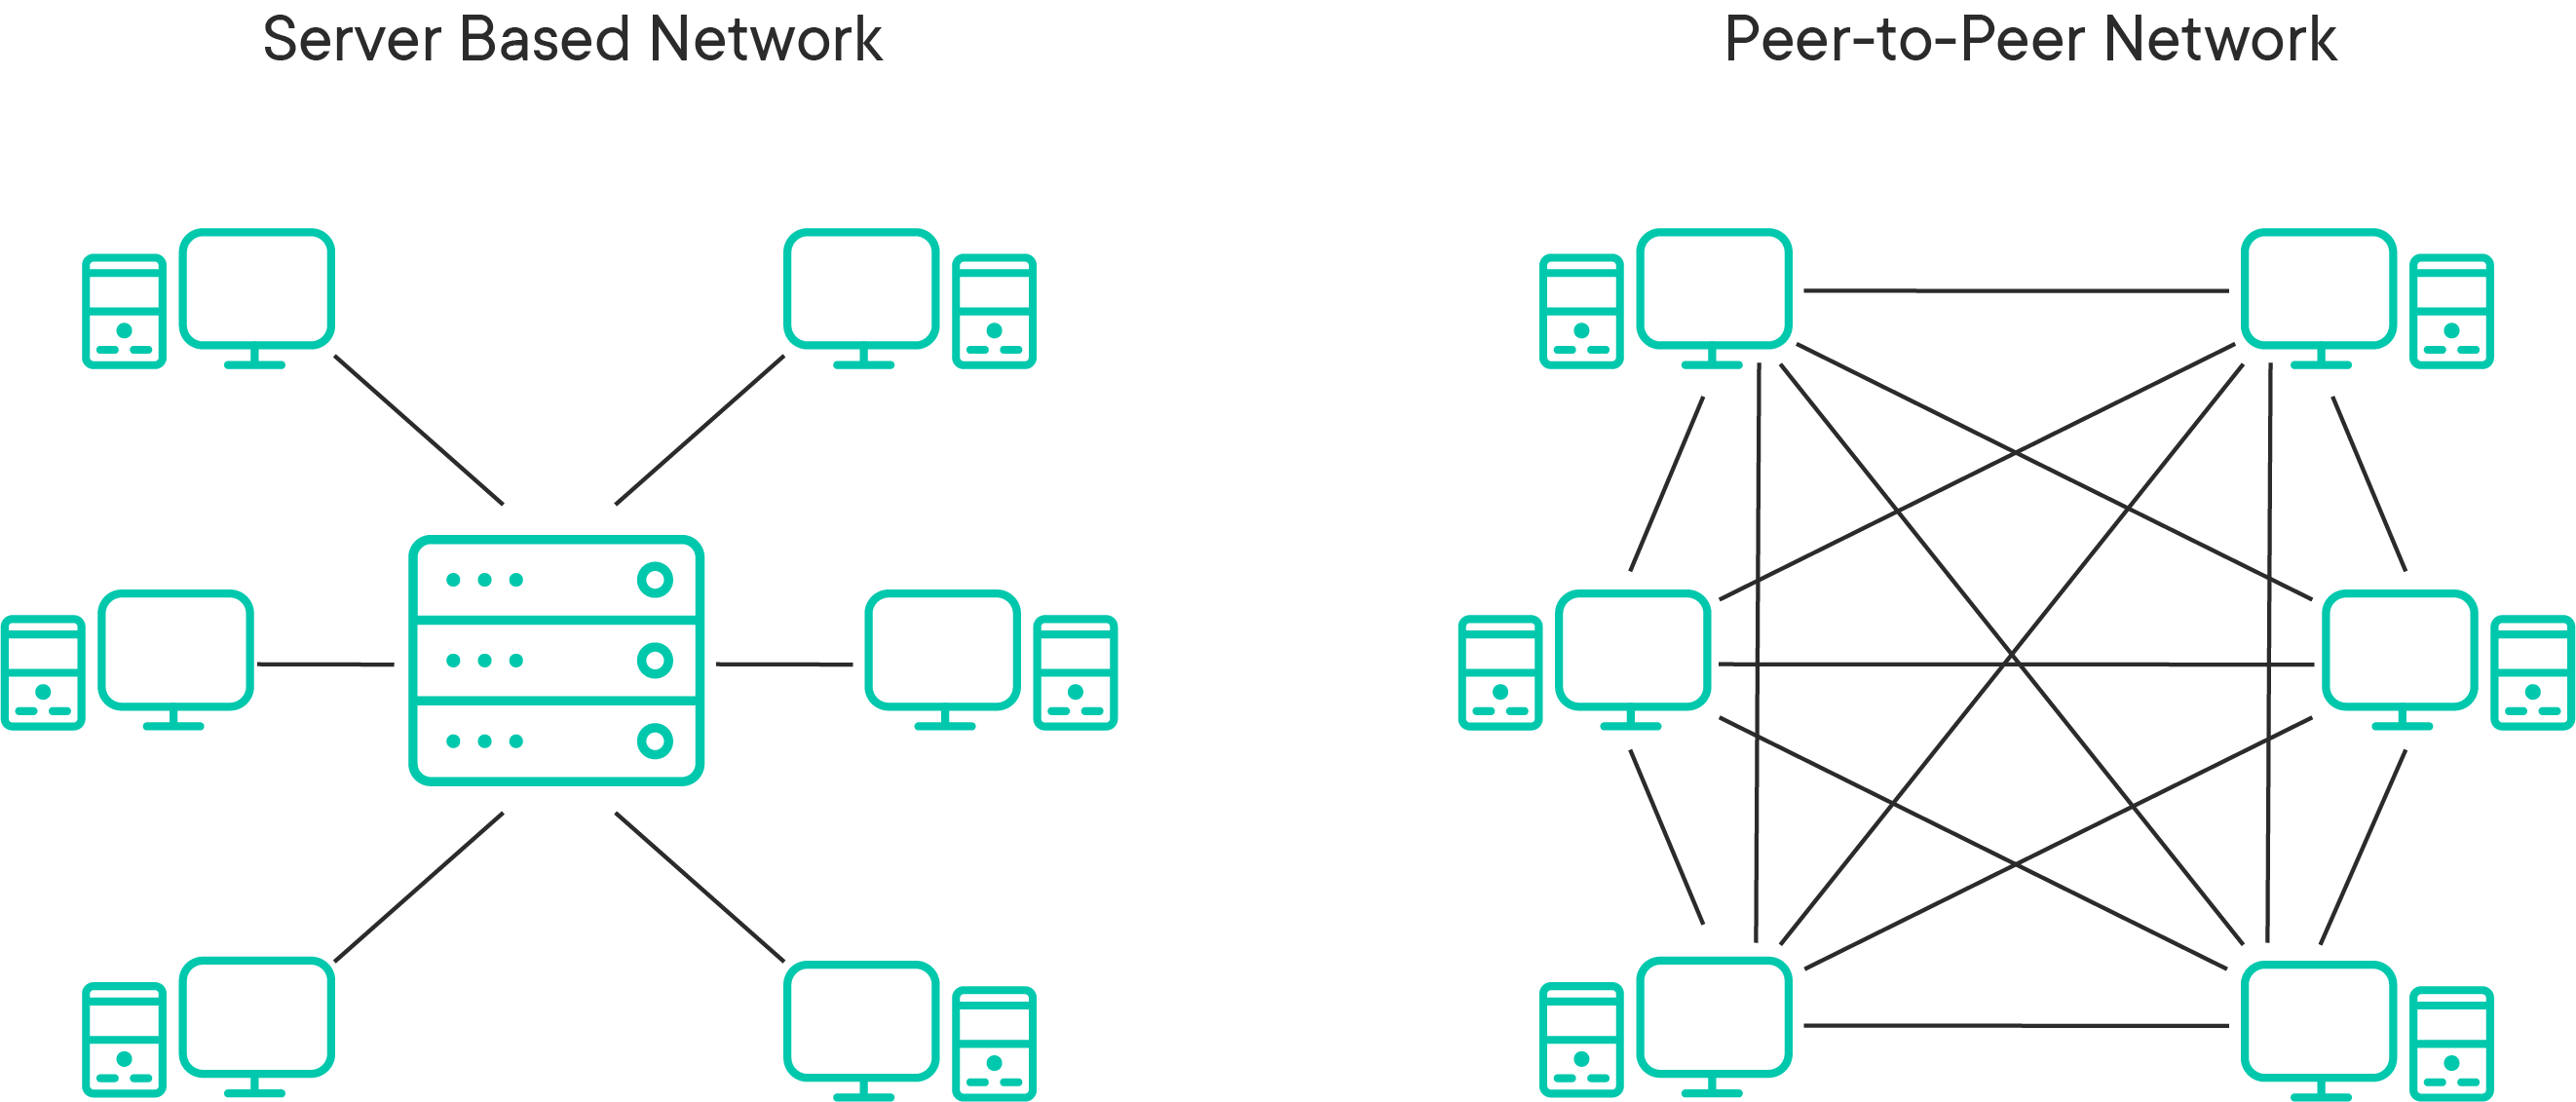

### Системы параллельной обработки

Эти системы полезны для многих приложений по всему Интернету, но они, как правило, плохо подходят для работы с вычислительной мощностью, необходимой для очень больших наборов данных и сложных проблем.

Когда есть чрезвычайно сложная задача, то лучше всего разделять ее на более простые задачи. В мире больших данных, если данные достаточно «большие», обычно лучше использовать подход разделения большой задачи на более мелкие части.

Несмотря на то, что отдельные процессоры становятся быстрее, они никогда не смогут справиться с объемом данных, который мы способны производить. Лучшим решением, разработанным специалистами по информатике, было использование мощности нескольких процессоров для выполнения одной и той же задачи. При использовании хорошо развитой распределенной системы несколько процессоров могут выполнять задачи за часть времени, которое потребовалось бы одному процессору. Как показано на рисунке ниже, если вы можете разделить работу между несколькими процессорами, все будет работать эффективнее.

При параллельных вычислениях:

* большая задача разбивается на более мелкие части
* каждая часть задачи следует за серией инструкций
* каждая из инструкций выполняется одновременно на разных процессорах
* все ответы собираются из небольших задач и объединяются в один окончательный ответ

На изображении ниже вы можете увидеть простой пример процесса, который разбивается и выполняется как последовательно, так и параллельно.

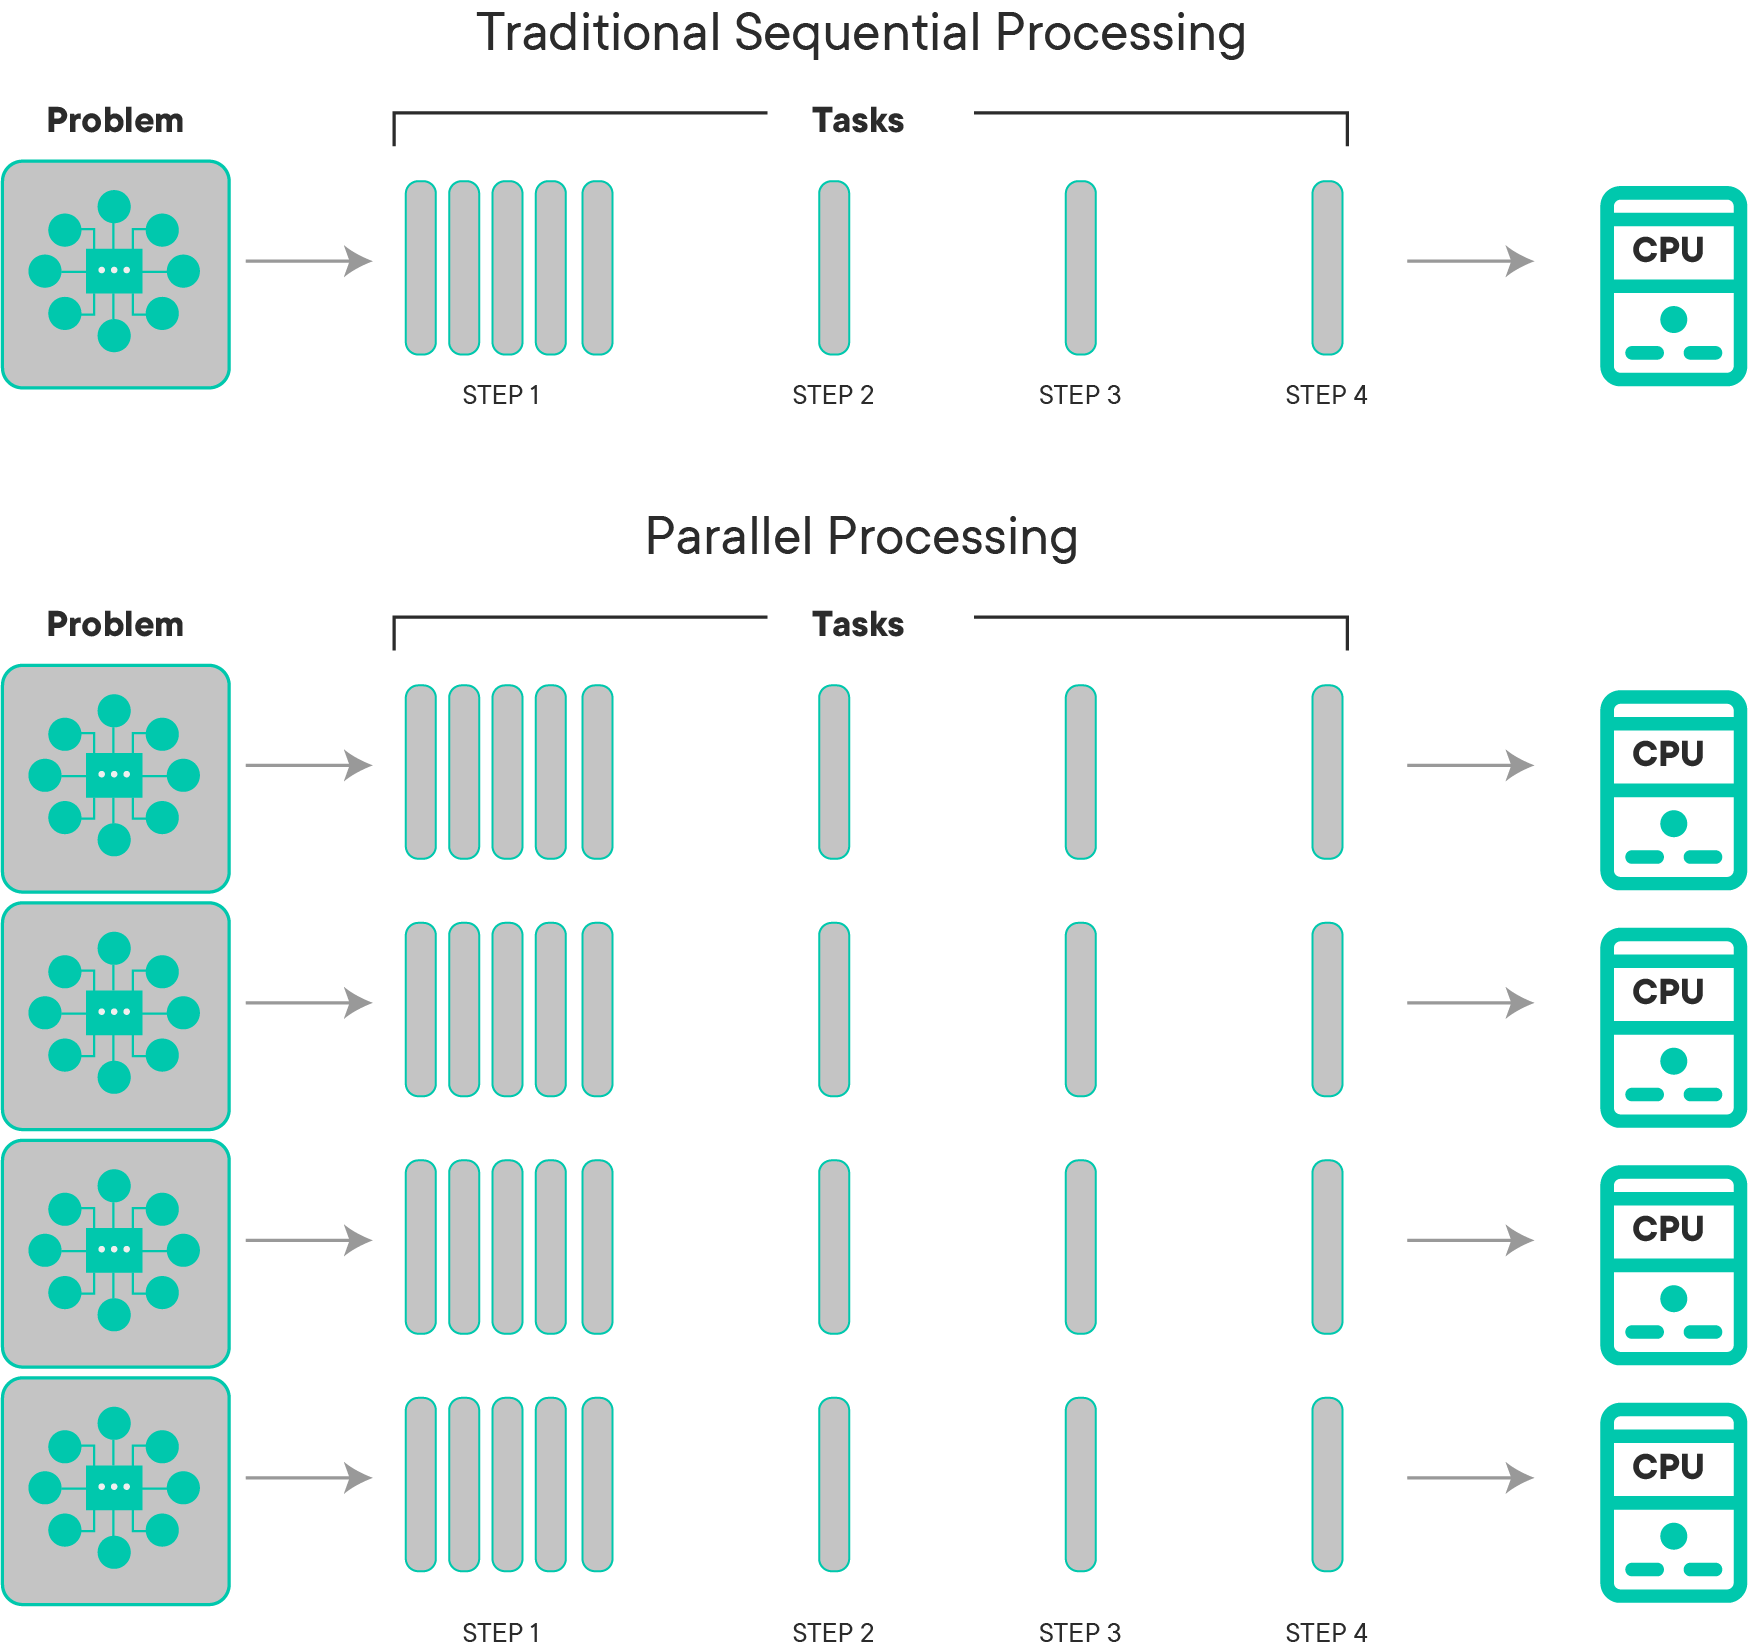

Конечно, не все задачи можно распараллелить, но есть некоторые задачи, которые не требуют практически никаких усилий для обеспечения того, чтобы ее распараллелить. Одним из примеров такой задачи может быть взлом пароля. Примером чего-то явно параллелизуемого может быть кинокомпания, пытающаяся подсчитать общую прибыль, которую она получила от всех фильмов, выпущенных ею в определенном году. Давайте подумаем обо всех компонентах, которые входят в определение того, является ли фильм прибыльным или нет.

* права на сюжет
* продюсер
* режиссер
* актерский состав
* затраты на производство
* визуальные эффекты
* музыка  

* (и, конечно же) кассовые сборы

Вот как это выглядело бы, если бы это вычислялось последовательно.

Если бы киностудия вычисляла прибыль каждого своего фильма последовательно, это заняло бы гораздо больше времени, чем если бы она вычисляла прибыль каждого фильма и объединяла их параллельно.

Вот схема того, как выглядит параллельная обработка в действиях

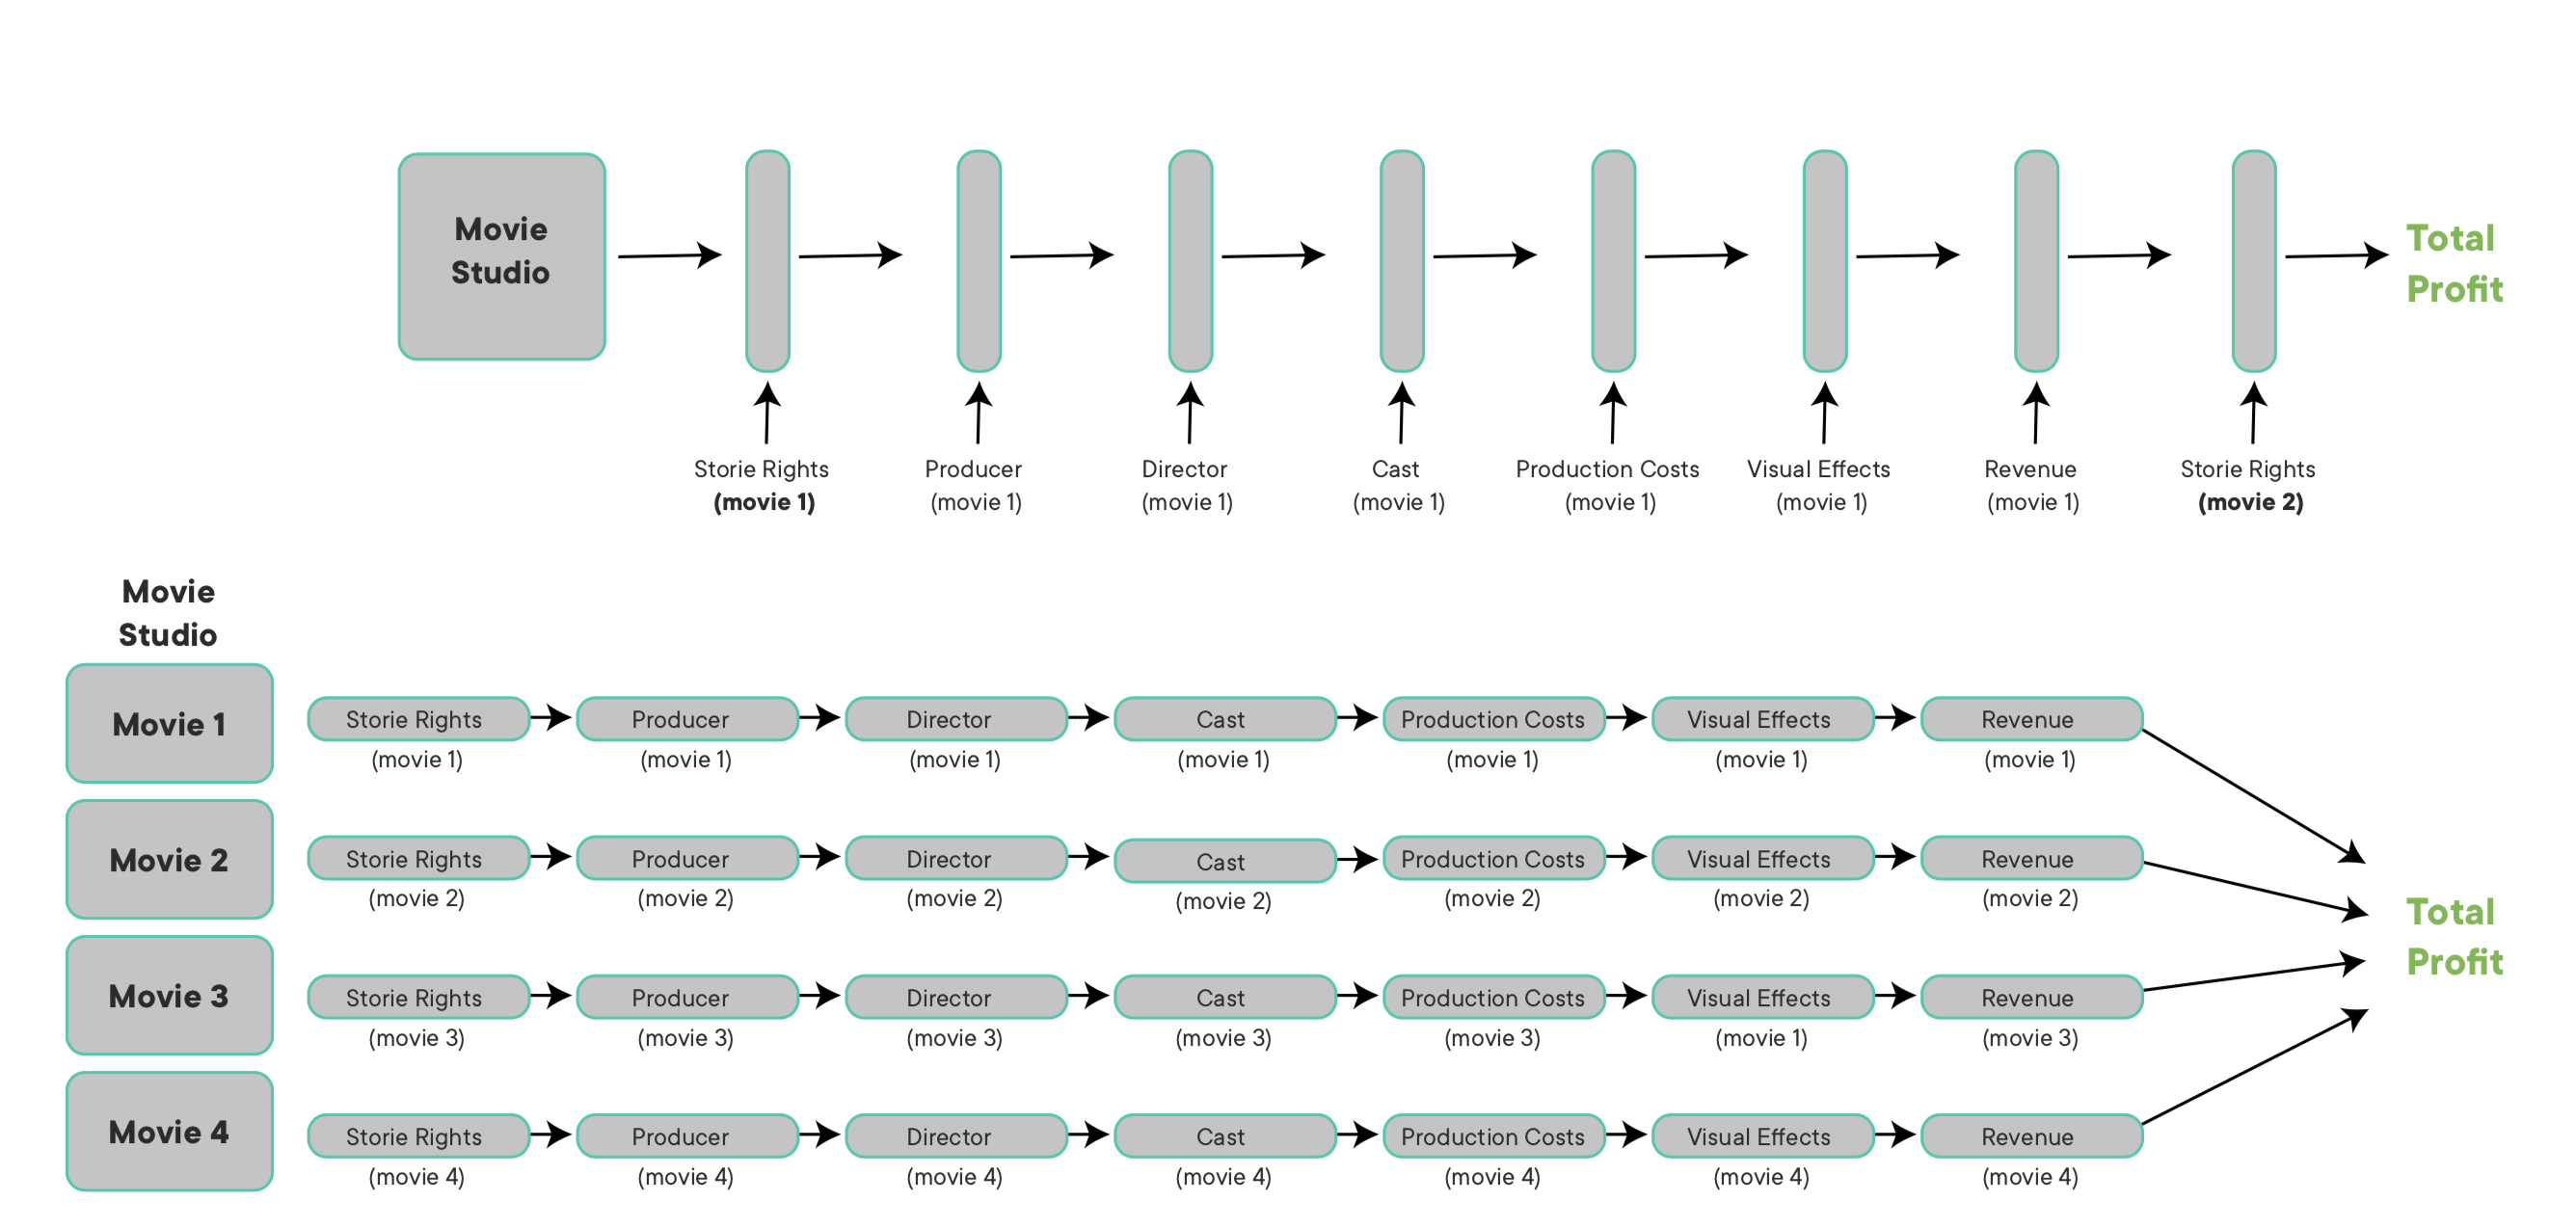

Можно заставить все эти узлы общаться друг с другом, используя парадигму программирования под названием __MapReduce__.

__MapReduce__ — это программная среда, разработанная для обработки наборов данных, которые квалифицируются как «большие данные», в распределенной и параллельной среде обработки на нескольких компьютерах/узлах, соединенных друг с другом как часть кластера. Это конкретный пример обобщенной техники _split-apply-combine_, используемой для выполнения различных анализов данных.

Рассмотрим простой пример подсчета слов, который демонстрирует работу MapReduce. Общая концепция MapReduce очень проста, но очень эффективна, поскольку:

* каким-либо образом все данные могут быть сопоставлены с парами <ключ:значение>.
* сами ключи и значения могут быть ЛЮБОГО типа данных.

Для нашего примера предположим, что национальная ассоциация зоопарков хочет определить общее количество видов животных в стране. Получив ответы от каждого зоопарка в стране, ответственный за них специалист по данным получает большой файл, в котором на каждой строке с видом в этом месте указан другой зоопарк.

Вот первые пять зоопарков, которые специалист по данным читает в полученном документе данных:

| Животные             |
|----------------------|
| lion tiger bear      |
| lion giraffe         |
| giraffe penguin      |
| penguin lion giraffe |
| koala giraffe        |

Рассмотрим, как можно использовать фреймворк MapReduce в этом простом примере задачи подсчета слов, который можно было бы обобщить для гораздо большего количества данных.

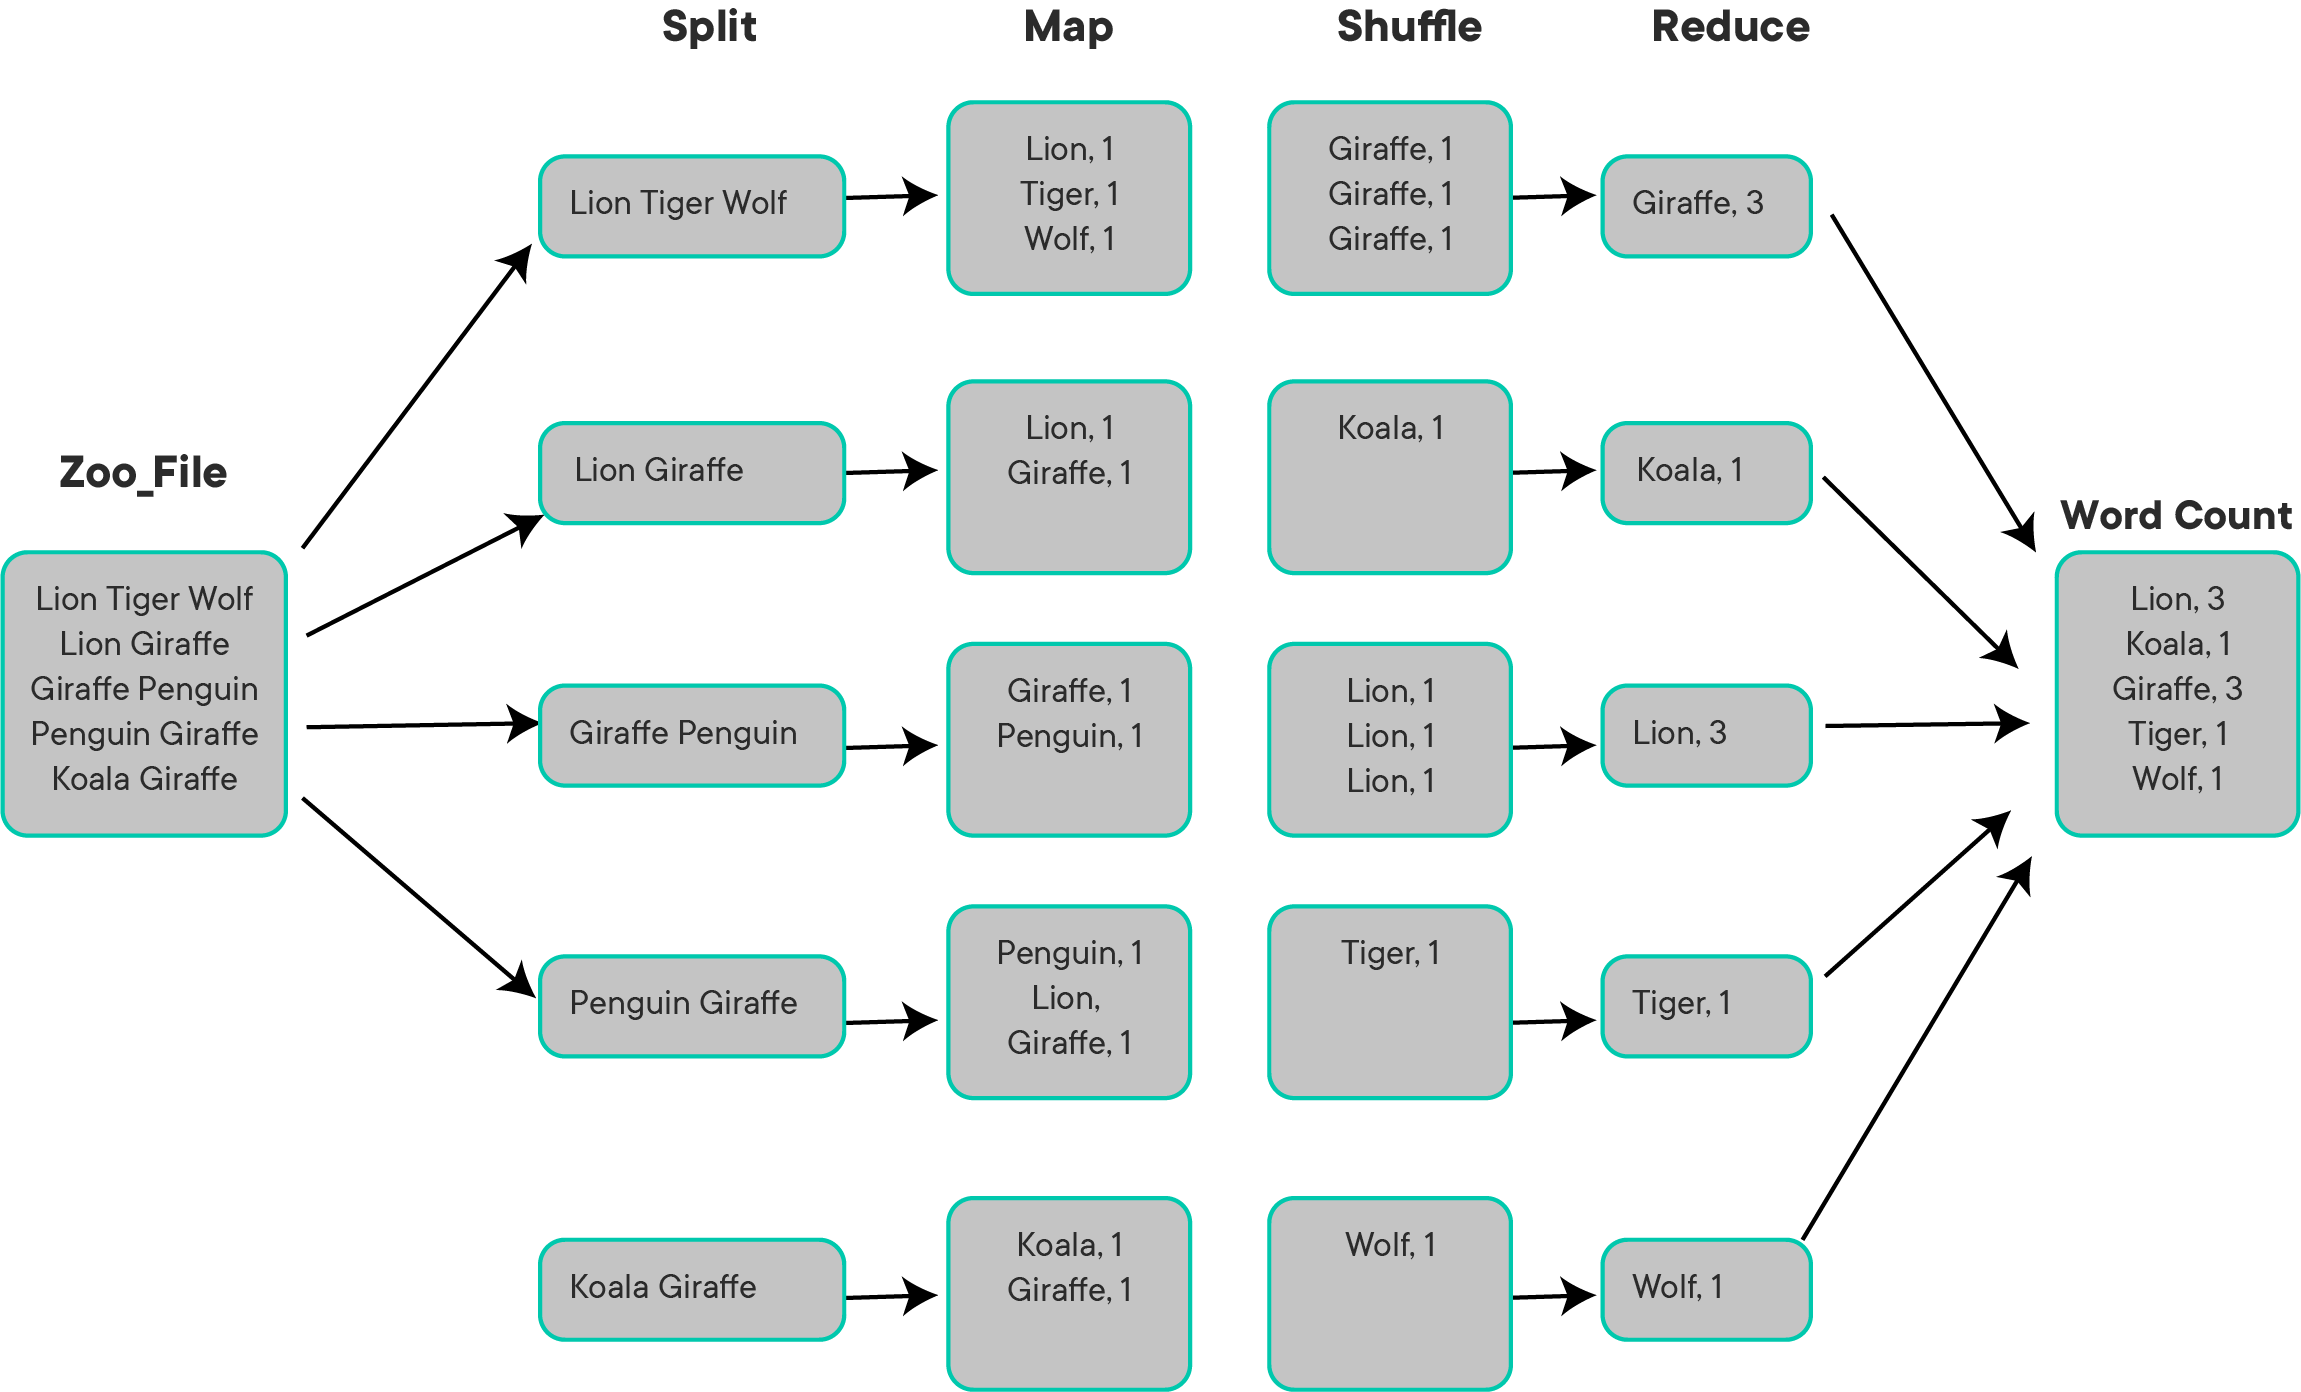

Посмотрим на изображение этого процесса в действии и определим, что на самом деле происходит.

### 1. Задание MAP (Splitting & Mapping)

Набор данных, который необходимо обработать, сначала должен быть преобразован в пары `ключ:значение` и разделен на фрагменты, которые затем назначаются заданиям MAP. Каждому вычислительному кластеру назначается ряд заданий MAP, которые впоследствии распределяются между его узлами. В этом примере предположим, что используется 5 узлов.

Сначала разделим данные из одного файла или файлов на столько узлов, сколько используется.

Затем используем функцию MAP для создания пар `ключ:значение`, представленных следующим образом:

`{животное}, {кол-во животных}`

После обработки исходных пар `ключ:значение` генерируются некоторые промежуточные пары `ключ:значение`. Промежуточные пары `ключ:значение` сортируются по их значениям ключей для создания нового списка пар `ключ:значение`.

### 2. Перемешивание (Shuffling)

Этот список из задания MAP делится на новый набор фрагментов, который сортирует и перемешивает отображенные объекты в порядок или группировку, которая облегчит выполнение задания REDUCE (свертки или сокращения). Количество этих новых фрагментов данных будет таким же, как и количество заданий REDUCE.

### 3. Задание REDUCE (Reduction)

Теперь к каждому правильно перемешанному фрагменту данных будет применено задание REDUCE. После завершения задания окончательный результат записывается в файловую систему. Базовой файловой системой обычно является HDFS (Hadoop Distributed File System).

Важно отметить, что подход MapReduce, как правило, будет эффективен только при работе с большими объемами данных. При использовании небольшого набора данных будет быстрее выполнять операции вне подхода MapReduce.

В этом процессе есть две группы узлов, которые гарантируют, что процесс MapReduce будет выполнен правильно:

* отслеживание работы (__Job Tracker__): «главный» узел, который информирует другие узлы о том, какие задания map и reduce необходимо выполнить

* отслеживание задач (__Task Tracker__): «рабочие» узлы, которые завершают операции map и reduce

Эти компоненты имеют разные названия в зависимости от используемой технологии, но всегда будет главный узел, который информирует рабочие узлы о том, какие задачи следует выполнить.

Общий псевдокод для заданий Map и Reduce в задаче подсчета количества слов выглядеть так:

```python
# Count word frequency
def map( doc ) :
    for word in doc.split( ' ' ) :
        emit ( word , 1 )

def reduce( key , values ) :
    emit ( key , sum( values ) )
```

Аналогично, можно объединять нескольких заданий MapReduce для выполнения заданной задачи. Это означает, что после завершения первого задания MapReduce выходные данные станут входными данными для второго задания MapReduce, и эти выходные данные могут быть конечным результатом (или переданы в другое задание MapReduce).

> __InputFile -> Map-1 -> Reduce1 -> output1 -> Map2 - > Reduce-2 -> output2 -> ....Map-x -> Reduce-x__  

## MapReduce в библиотеке mrjob

Библиотека __mrjob__ позволяет выполнять задания MapReduce в различных средах.

Библиотека устанавливается командой терминала
```
pip install mrjob
```
Программа Python, использующая `mrjob`, запускается из терминала командой вида
```
python <имя программы> <имя обрабатываемого файла>
```

Версия Python должна быть не выше 3.12, так как начиная с версии 3.13 в Python перестал поддерживаться модуль `pipes`, к которому обращается библиотека `mrjob`.

In [45]:
import random

contenders = ['Kill The Love', 'Dynamite', 'Likey']

# generate 10 songs chosen randomly from contenders
# use random.choices() to draw samples with replacement
# argument 'k' to specify how many samples to draw
random.choices(contenders, k=10)

['Dynamite',
 'Kill The Love',
 'Likey',
 'Kill The Love',
 'Likey',
 'Dynamite',
 'Dynamite',
 'Likey',
 'Likey',
 'Likey']

In [46]:
# Generate a list of 2000 songs
song_list = random.choices(contenders, k=2000)

# write the song list to a file, each entry separated by newline
with open('songs.txt', 'w') as myfile:
    myfile.write('\n'.join(song_list))

In [47]:
!tail songs.txt

Dynamite
Dynamite
Dynamite
Likey
Dynamite
Likey
Kill The Love
Kill The Love
Dynamite
Dynamite

In [48]:
%%file MR_wordcount.py
# %%file is an Ipython magic function that saves the code cell as a file

from mrjob.job import MRJob # import the mrjob library

class MRSongCount(MRJob):

    # the map step: each line in the txt file is read as a key, value pair
    # in this case, each line in the txt file only contains a value but no key
    # _ means that in this case, there is no key for each line
    def mapper(self, _, song):
        # output each line as a tuple of (song_names, 1)
        yield (song, 1)

    # the reduce step: combine all tuples with the same key
    # in this case, the key is the song name
    # then sum all the values of the tuple, which will give the total song plays
    def reducer(self, key, values):
        yield (key, sum(values))

if __name__ == "__main__":
    MRSongCount.run()

Overwriting MR_wordcount.py


In [49]:
!cat MR_wordcount.py

# %%file is an Ipython magic function that saves the code cell as a file

from mrjob.job import MRJob # import the mrjob library

class MRSongCount(MRJob):

    # the map step: each line in the txt file is read as a key, value pair
    # in this case, each line in the txt file only contains a value but no key
    # _ means that in this case, there is no key for each line
    def mapper(self, _, song):
        # output each line as a tuple of (song_names, 1)
        yield (song, 1)

    # the reduce step: combine all tuples with the same key
    # in this case, the key is the song name
    # then sum all the values of the tuple, which will give the total song plays
    def reducer(self, key, values):
        yield (key, sum(values))

if __name__ == "__main__":
    MRSongCount.run()


В результате записан файл `MR_wordcount.py`, который можно запустить на выполнение в терминале.

Библиотеке `mrjob` требуется модуль `pipes`, который ранее входил в стандартную библиотеку языка Python. Однако начиная с версии 3.13 языка Python этот модуль исключен из стандартной библиотеки, поэтому приходится вызывать интерпретатор Python версии 3.12 из другого окружения (окружения AIFin).  

Используем в дальнейших примерах набор данных Student Performance (https://archive.ics.uci.edu/dataset/320/student+performance), состоящий из 649 записей и имеющий 30 признаков (файл `student-mat.csv`).

In [50]:
!tail student-mat.csv

"MS";"F";18;"R";"GT3";"T";2;2;"at_home";"other";"other";"mother";2;3;0;"no";"no";"yes";"no";"yes";"yes";"no";"no";5;3;3;1;3;4;2;"10";"9";10
"MS";"F";18;"R";"GT3";"T";4;4;"teacher";"at_home";"reputation";"mother";3;1;0;"no";"yes";"yes";"yes";"yes";"yes";"yes";"yes";4;4;3;2;2;5;7;"6";"5";6
"MS";"F";19;"R";"GT3";"T";2;3;"services";"other";"course";"mother";1;3;1;"no";"no";"no";"yes";"no";"yes";"yes";"no";5;4;2;1;2;5;0;"7";"5";0
"MS";"F";18;"U";"LE3";"T";3;1;"teacher";"services";"course";"mother";1;2;0;"no";"yes";"yes";"no";"yes";"yes";"yes";"no";4;3;4;1;1;1;0;"7";"9";8
"MS";"F";18;"U";"GT3";"T";1;1;"other";"other";"course";"mother";2;2;1;"no";"no";"no";"yes";"yes";"yes";"no";"no";1;1;1;1;1;5;0;"6";"5";0
"MS";"M";20;"U";"LE3";"A";2;2;"services";"services";"course";"other";1;2;2;"no";"yes";"yes";"no";"yes";"yes";"no";"no";5;5;4;4;5;4;11;"9";"9";9
"MS";"M";17;"U";"LE3";"T";3;1;"services";"services";"course";"mother";2;1;0;"no";"no";"no";"no";"no";"yes";"yes";"no";2;4;5;3;4;2;3;"14";"16";16
"

##### __Пример подсчета количества (count)__

Для подсчета количества студентов функция __mapper__ выдаёт пары «ключ-значение», где ключ — это поле для группировки, а значение — «1» или любые связанные элементы, необходимые для вычисления количества студентов. Функция __reducer__
получает пары «ключ-значение», сгруппированные по одному и тому же ключу, и суммирует значения для каждой группы для вычисления количества студентов. 

Рассмотрим программу, которая подсчитывает количество записей в наборе данных для каждого возраста учащегося.
В этом примере функция mapper анализирует каждую строку входных данных и выдаёт пары «ключ-значение», где ключ — это возраст, а значение — «1». Функция reducer получает список значений, сгруппированных по ключу, и суммирует их для вычисления количества студентов.


In [51]:
%%file MR_stud_age.py

#Total number of students for each age
from mrjob.job import MRJob

class MRmyjob(MRJob):
    def mapper(self, _, line):
        #Split the line with semicolon separated fields
        data=line.split(';')

        #Parse line
        age = data[2].strip()

        #Emit age and 1
        if age.isnumeric():
            yield age, 1

    def reducer(self, key, list_of_values):
        yield key,sum(list_of_values)

if __name__ == '__main__':
    MRmyjob.run()

Overwriting MR_stud_age.py


In [52]:
! ~/miniforge3/envs/main/bin/python MR_stud_age.py student-mat.csv

No configs found; falling back on auto-configuration
No configs specified for inline runner
Creating temp directory /var/folders/g7/1pnn3np5387b0n86j69n94v40000gn/T/MR_stud_age.arsknz.20260905.071857.541566
Running step 1 of 1...
job output is in /var/folders/g7/1pnn3np5387b0n86j69n94v40000gn/T/MR_stud_age.arsknz.20260905.071857.541566/output
Streaming final output from /var/folders/g7/1pnn3np5387b0n86j69n94v40000gn/T/MR_stud_age.arsknz.20260905.071857.541566/output...
"21"	1
"22"	1
"17"	98
"18"	82
"19"	24
"20"	3
"16"	104
"15"	82
Removing temp directory /var/folders/g7/1pnn3np5387b0n86j69n94v40000gn/T/MR_stud_age.arsknz.20260905.071857.541566...


##### __Пример вычисления среднего значения__

Для вычисления среднего значения функция mapper выдаёт пары "ключ-значение", где ключ — это поле,
по которому производится группировка, а значение — связанные элементы, необходимые для вычисления среднего значения. Функция reducer
получает список значений, сгруппированных по одному и тому же ключу, и находит среднее значение.

Рассмотрим пример вычисления среднего итогового балла для каждого уровня здоровья студентов.  Функция mapper
в этом примере анализирует каждую строку входных данных и выдаёт пары ключ-значение, где ключ — это
уровень здоровья, а значение — итоговый балл. Функция reducer получает список значений, сгруппированных по ключу
(который является уровнем здоровья), и находит среднее значение этих значений.

In [53]:
%%file MR_health_G3.py

#Average final grade G3 for each health level
from mrjob.job import MRJob

class MRmyjob(MRJob):
    def mapper(self, _, line):
        #Split the line with tab separated fields
        data=line.split(';')

        #Parse line
        health = data[28].strip()
        if health.isnumeric():
            G3 = int(data[32].strip())
            yield health, G3

    def reducer(self, key, list_of_values):
        count = 0
        total = 0.0
        for x in list_of_values:
            total += x
            count += 1
        avgLen = ("%.2f" % (total/count))
        yield key, avgLen

if __name__ == '__main__':
    MRmyjob.run()

Overwriting MR_health_G3.py


In [54]:
! /opt/anaconda3/envs/AIFin/bin/python MR_health_G3.py student-mat.csv

zsh:1: no such file or directory: /opt/anaconda3/envs/AIFin/bin/python


При обработке данных можно одновременно вычислять несколько показателей.

In [55]:
%%file MR_count_all.py

# Подсчет различных характеристик текста
from mrjob.job import MRJob

class MRWordCountUtility(MRJob):

    def __init__(self, *args, **kwargs):
        super(MRWordCountUtility, self).__init__(*args, **kwargs)
        self.chars = 0
        self.words = 0
        self.lines = 0

    def mapper(self, _, line):
        # Don't actually yield anything for each line. Instead, collect them
        # and yield the sums when all lines have been processed. The results
        # will be collected by the reducer.
        self.chars += len(line) + 1  # +1 for newline
        self.words += sum(1 for word in line.split() if word.strip())
        self.lines += 1

    def mapper_final(self):
        yield('chars', self.chars)
        yield('words', self.words)
        yield('lines', self.lines)

    def reducer(self, key, values):
        yield(key, sum(values))

if __name__ == '__main__':
    MRWordCountUtility.run()

Overwriting MR_count_all.py


In [56]:
! /opt/anaconda3/envs/AIFin/bin/python MR_count_all.py MR_count_all.py

zsh:1: no such file or directory: /opt/anaconda3/envs/AIFin/bin/python


В базовом MapReduce одна задача состоит из одной фазы Map и одной фазы Reduce. Но в реальной жизни данные редко укладываются в такую простую схему.

__Многошаговый MapReduce__ (Multi-step MapReduce) — это паттерн, при котором выходной данные одного MapReduce-шага становятся входными данными для следующего.

__Зачем это нужно?__

* __Снижение сложности__: Разбиение сложной бизнес-логики на простые, атомарные шаги.
* __Управление памятью__: Если в одном редьюсере нужно обработать слишком много данных, мы можем сначала сгруппировать их (Шаг 1), а затем агрегировать (Шаг 2).
* __Повторное использование промежуточных данных__: Промежуточный результат может быть полезен сам по себе или использоваться в других аналитических цепочках.


Когда вы запускаете многошаговую задачу в `mrjob` (особенно в кластере Hadoop/EMR):

- Выполняется Шаг 1. Его результат записывается в промежуточные файлы (в HDFS или локальную временную папку).
- Фреймворк выполняет Sort & Shuffle для промежуточных данных.
- Выполняется Шаг 2, читая данные из промежуточных файлов.
- Финальный результат записывается в итоговое хранилище.

В локальном режиме `mrjob` эмулирует этот процесс, создавая временные файлы, чтобы поведение было идентично кластерному.

### Синтаксис mrjob: Метод steps()

В `mrjob` многошаговость реализуется через переопределение метода `steps()` в вашем классе. Этот метод должен возвращать список объектов, где каждый объект описывает один шаг.

### Практический пример: Анализ веб-логов

Допустим, что у нас есть логи веб-сервера. Нам нужно найти топ-3 самых частых кодов ответа (HTTP Status) для каждого IP-адреса. Но чтобы не засорять отчет, мы должны вывести только те IP-адреса, которые сделали не менее 5 запросов суммарно.

Почему это нельзя сделать в один шаг? В одном шаге мы можем посчитать частоту статусов для IP. Но чтобы отфильтровать IP по общему количеству запросов (>4) и взять топ-3, нам нужно сначала получить полную статистику по каждому IP, а уже затем применять фильтрацию и сортировку.

Входные данные:

In [57]:
import pandas as pd

df = pd.read_csv("access_logs.csv") # huggingface.co

df[['ip_address','status_code']]

,ip_address,status_code
0,107.8.181.20,201
1,167.4.254.26,304
2,93.47.67.36,200
3,189.113.25.154,201
4,168.210.20.247,200
...,...,...
4995,141.231.128.247,200
4996,130.238.7.78,200
4997,213.118.195.73,401
4998,113.139.175.204,200


In [58]:
df[['ip_address','status_code']].to_csv(
    'input.txt', sep='\t', index=False, header=False
)

### Особенности кода:

- __Маппер второго шага__: В mrjob можно полностью убрать маппер на втором шаге. Если шаг состоит только из редьюсера, mrjob автоматически передаст данные из `step1_reducer` напрямую в `step2_reducer`. 
- __Редьюсер второго шага__: Так как на Шаге 1 мы сгруппировали данные по IP, в Шаге 2 для каждого IP придет ровно одно значение. Поэтому мы используем `next(data_list)`, чтобы достать его, не используя циклы.

In [59]:
%%file MR_TopStatusesPerIP.py
from mrjob.job import MRJob
from mrjob.step import MRStep

class TopStatusesPerIP(MRJob):

    def steps(self):
        # Убираем step2_mapper. mrjob связывает reducer1 -> reducer2 напрямую
        return [
            MRStep(mapper=self.step1_mapper, reducer=self.step1_reducer),
            MRStep(reducer=self.step2_reducer)
        ]

    # ==========================================
    # ШАГ 1: Подсчет частоты статусов для каждого IP
    # ==========================================
    
    def step1_mapper(self, key, line):
        parts = line.split('\t')
        if len(parts) == 2:
            ip, status = parts
            yield ip, status

    def step1_reducer(self, ip, statuses):
        counts = {}
        total_requests = 0
        
        for status in statuses:
            counts[status] = counts.get(status, 0) + 1
            total_requests += 1
            
        # Передаем обычный словарь. mrjob сам сериализует его под капотом.
        result_data = {
            'total': total_requests,
            'counts': counts
        }
        yield ip, result_data

    # ==========================================
    # ШАГ 2: Фильтрация и выбор Топ-3 (Данные идут напрямую из reducer1)
    # ==========================================
    
    def step2_reducer(self, ip, data_list):
        # Так как ключи IP уникальны после Шага 1, в data_list будет ровно 1 элемент
        data = next(data_list)
        
        total = data['total']
        counts = data['counts']
        
        # Фильтр: только если запросов > 4
        if total > 4:
            # Сортируем статусы по убыванию частоты (x[1] - это count)
            sorted_statuses = sorted(
                counts.items(), key=lambda x: x[1], reverse=True
            )
            
            # Берем топ-3
            top_3 = sorted_statuses[:3]
            
            # Форматируем красивый вывод
            top_3_str = ", ".join(
                [f"{status}({count})" for status, count in top_3]
            )
            yield ip, f"Total: {total} | Top 3 statuses: {top_3_str}"

if __name__ == '__main__':
    TopStatusesPerIP.run()

Overwriting MR_TopStatusesPerIP.py


In [60]:
!/opt/anaconda3/envs/AIFin/bin/python MR_TopStatusesPerIP.py input.txt 

zsh:1: no such file or directory: /opt/anaconda3/envs/AIFin/bin/python


## Задание к теме №1

Даны 10 файлов с текстами коротких рассказов на английском языке (`story_0.txt` ... `story_9.txt`). 
В соответствии с **последней цифрой номера вашего студенческого билета**, выберите один файл для обработки и вариант задания. 

Требуется реализовать **многошаговый (Multi-step)** MapReduce алгоритм с использованием библиотеки `mrjob`. Использование стандартных Python-структур для накопления данных в памяти внутри Reducer (например, `list(values)`, `set()`, `collections.Counter` для всего объема) **запрещено**. Данные должны обрабатываться потоково (итеративно).

Общие требования:
1. **Архитектура:** Каждый вариант состоит ровно из **двух шагов** (Step 1 и Step 2), реализованных через метод `steps()`.
2. **Предобработка текста:** Во всех вариантах текст должен быть приведен к нижнему регистру. Знаки препинания в конце и начале слов должны быть удалены.